# Analyse en composantes principales (ACP) du Wine Quality Dataset

**Problématique :** que distingue les vins entre eux, et ces différences sont-elles liées à la qualité ?

**Données :** Wine Quality Dataset (UCI Machine Learning Repository), vins portugais *vinho verde* : 1599 vins rouges et 4898 vins blancs, décrits par 11 mesures physico-chimiques et une note de qualité attribuée par des dégustateurs.

**Méthode :** ACP normée programmée à la main avec NumPy, puis validée avec scikit-learn. La note de qualité n'entre pas dans l'ACP : elle sert seulement à colorer les graphiques (variable illustrative).

**Plan :** 1. Chargement et contrôle des données, 2. Analyse univariée, 3. Analyse bivariée, 4. ACP normée à la main, 5. Projections des vins, 6. Cercles des corrélations, 7. Vérification avec scikit-learn, 8. Vins rouges et blancs, 9. Conclusion et limites.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

os.makedirs('images', exist_ok=True)   # dossier où sont enregistrées les figures

**Source des données et citation**

P. Cortez, A. Cerdeira, F. Almeida, T. Matos et J. Reis. *Modeling wine preferences by data mining from physicochemical properties.* Decision Support Systems, Elsevier, 47(4):547-553, 2009.

Les fichiers sont dans le dossier `data/` (la description des variables est dans le fichier `winequality.names` fourni par l'UCI).

## 1. Chargement et contrôle des données

Importation du dataFrame

In [2]:
df=pd.read_csv('data/winequality-red.csv',sep=";")

In [3]:
df.head()

   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]

Analyse des dimensions de la base

info

In [4]:
df.shape

(1599, 12)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Analyse du type des données

In [6]:
df.dtypes.value_counts()

float64    11
int64       1
Name: count, dtype: int64

Analyse des données manquantes

In [7]:
(df.isnull()).sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [8]:
print("Nombre de doublons (vins rouges) :", df.duplicated().sum())

Nombre de doublons (vins rouges) : 240

**Décision :** les 240 doublons sont conservés. Ce sont des mesures chimiques plausibles de vins distincts, qui peuvent avoir les mêmes caractéristiques.

## 2. Analyse univariée

Analyse descriptives Univariés

In [9]:
df.describe()

       fixed acidity  volatile acidity  ...      alcohol      quality
count    1599.000000       1599.000000  ...  1599.000000  1599.000000
mean        8.319637          0.527821  ...    10.422983     5.636023
std         1.741096          0.179060  ...     1.065668     0.807569
min         4.600000          0.120000  ...     8.400000     3.000000
25%         7.100000          0.390000  ...     9.500000     5.000000
50%         7.900000          0.520000  ...    10.200000     6.000000
75%         9.200000          0.640000  ...    11.100000     6.000000
max        15.900000          1.580000  ...    14.900000     8.000000

[8 rows x 12 columns]

On constate que l'ecart type de chlorides est très négligeable par rapport a total sulfur, les données ne sont pas sur le meme echelle

### Pourquoi normaliser ?

calculons la part de variance expliquée =variance de j/variance totale*100

In [10]:
X=df.drop('quality',axis=1)
y=df['quality']

In [11]:
Variances=X.var(ddof=0)            # variance avec division par n, comme dans le cours
Variance_totale=Variances.sum()
part_var=Variances/Variance_totale*100

In [12]:
round(part_var,2)

fixed acidity            0.25
volatile acidity         0.00
citric acid              0.00
residual sugar           0.17
chlorides                0.00
free sulfur dioxide      9.13
total sulfur dioxide    90.34
density                  0.00
pH                       0.00
sulphates                0.00
alcohol                  0.09
dtype: float64

`total sulfur dioxide` explique à lui seul 90,34 % de la variance totale, et `free sulfur dioxide` 9,13 %. Les neuf autres variables se partagent environ 0,5 %.

Sans réduction, le premier axe ne serait que l'axe du dioxyde de soufre, un effet des unités de mesure. Il faut donc **centrer et réduire** les variables (ACP normée).

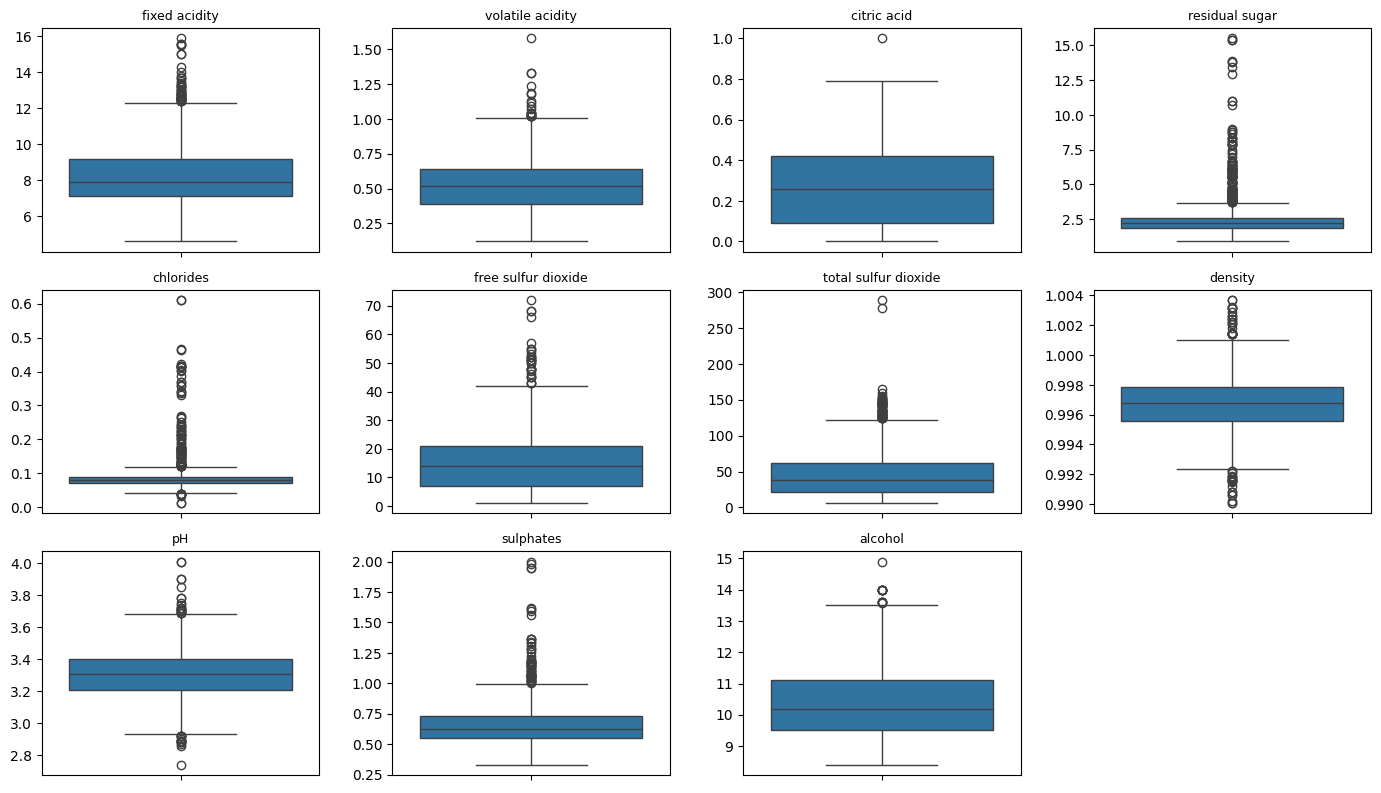

In [13]:
# Un boxplot par variable (chaque variable a sa propre échelle)
fig, axs = plt.subplots(3, 4, figsize=(14, 8))
for ax_, col in zip(axs.flatten(), X.columns):
    sns.boxplot(y=X[col], ax=ax_)
    ax_.set_title(col, fontsize=9)
    ax_.set_ylabel('')
axs.flatten()[-1].axis('off')          # la 12e case reste vide
plt.tight_layout()
plt.show()

Chaque variable a sa propre échelle, d'où un boxplot par variable. Plusieurs variables sont très asymétriques, avec de nombreuses valeurs extrêmes, surtout `chlorides` (asymétrie de 5,7), `residual sugar` (4,5) et `sulphates` (2,4).

In [14]:
Q1 = X.quantile(0.25)                  # premier quartile de chaque variable
Q3 = X.quantile(0.75)                  # troisième quartile
IQR = Q3 - Q1

outliers = (X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)   # tableau de True/False

print(outliers.sum())                  # nombre de valeurs extrêmes par variable
print("Vins avec au moins une valeur extrême :", outliers.any(axis=1).sum())

fixed acidity            49
volatile acidity         19
citric acid               1
residual sugar          155
chlorides               112
free sulfur dioxide      30
total sulfur dioxide     55
density                  45
pH                       35
sulphates                59
alcohol                  13
dtype: int64
Vins avec au moins une valeur extrême : 405

**Décision :** les valeurs extrêmes sont conservées. Ce sont des mesures chimiques plausibles et non des erreurs de saisie. L'ACP y est sensible : on le rappelle dans les limites (leur influence n'a pas été testée).

histogramme

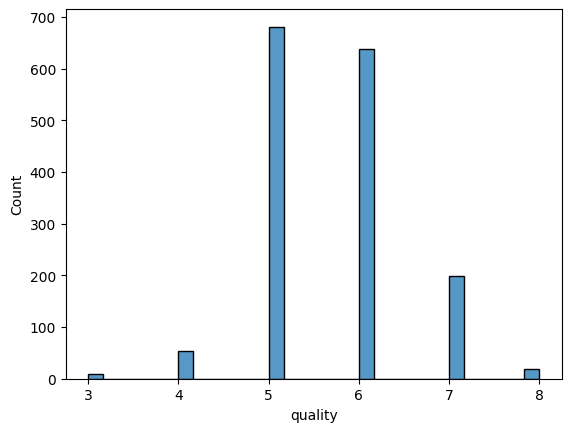

<Axes: xlabel='quality', ylabel='Count'>

In [15]:
sns.histplot(data=df,x='quality')

## 3. Analyse bivariée

Analyse bivariés

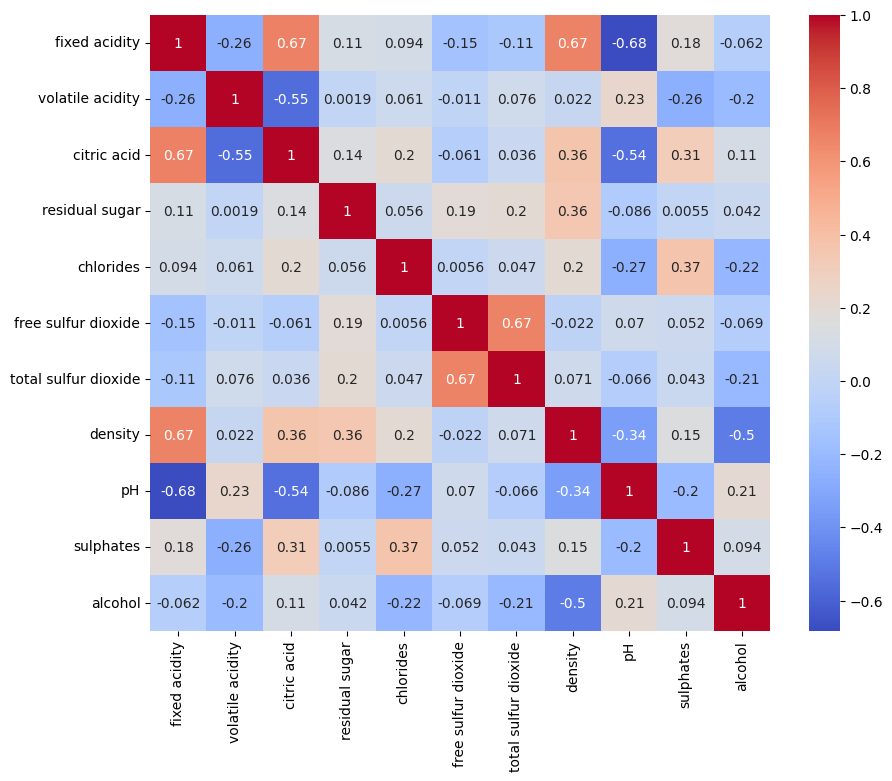

<Axes: >

In [16]:
plt.figure(figsize=(10,8))
corr_matrix=X.corr()
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm')

Les corrélations restent au plus moyennes : la plus forte vaut environ 0,68 en valeur absolue (`fixed acidity` et `pH`). Plusieurs variables sont tout de même liées entre elles, ce qui justifie une ACP.

Pairplot

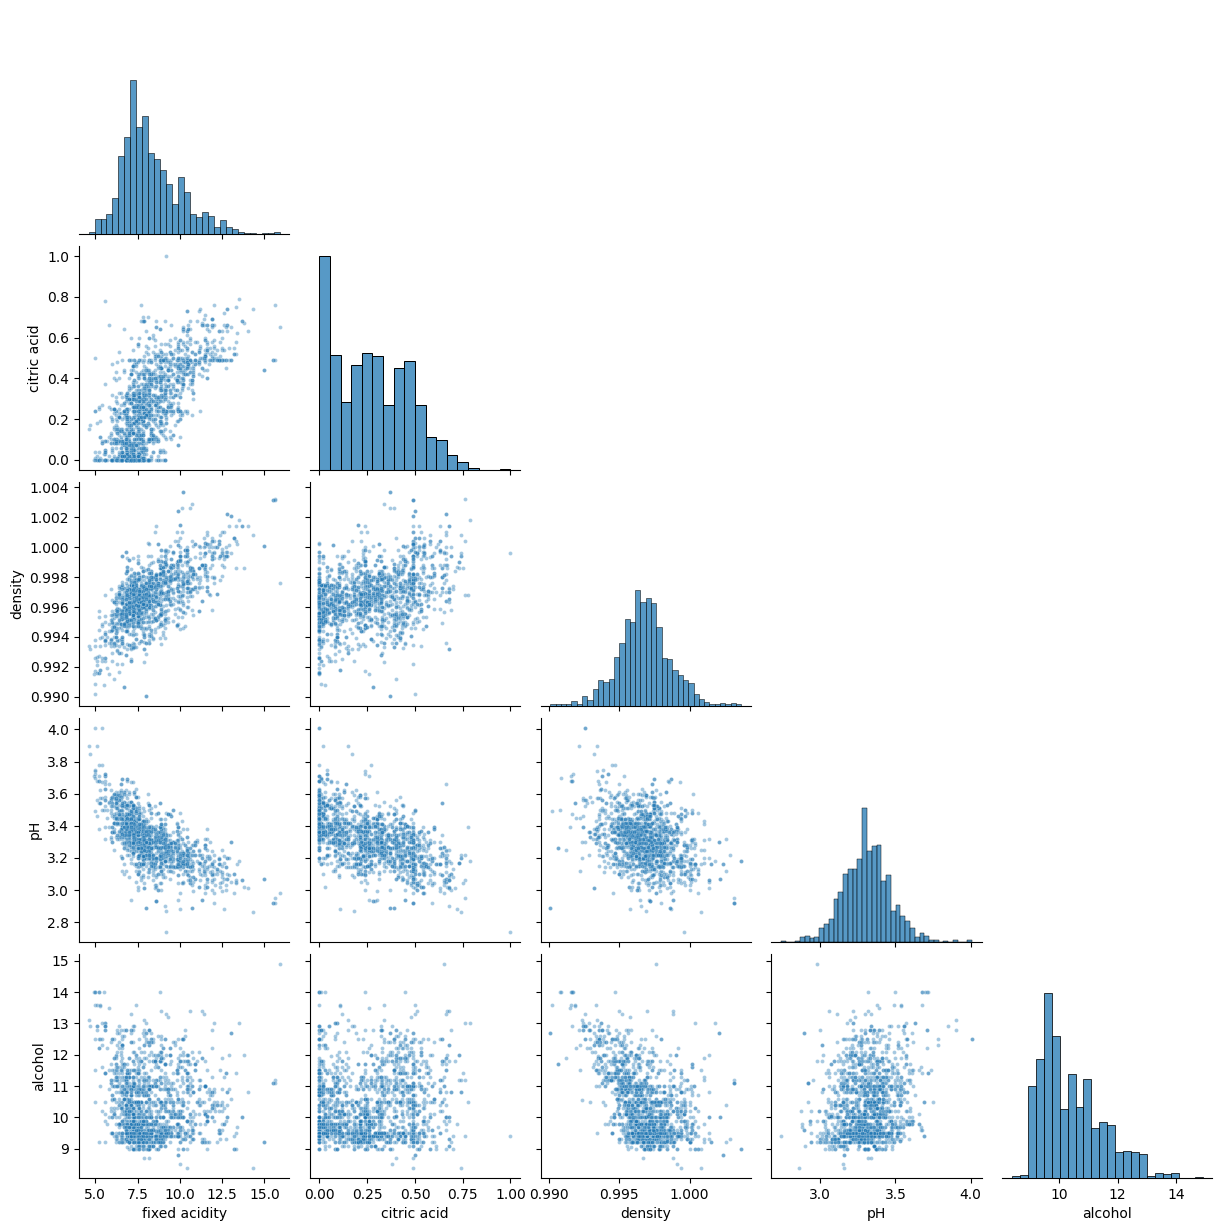

In [17]:
# Pairplot sur 5 variables (le pairplot complet est illisible et très lourd)
sel = ['fixed acidity', 'citric acid', 'density', 'pH', 'alcohol']
sns.pairplot(df[sel], corner=True, plot_kws={'s': 8, 'alpha': 0.4})
plt.show()

## 4. ACP normée à la main (NumPy)

### Centrage-réduction

Centrage et réduction des données

In [18]:
Xcr=(X-X.mean())/np.sqrt(X.var(ddof=0))

In [19]:
Xcr

      fixed acidity  volatile acidity  ...  sulphates   alcohol
0         -0.528360          0.961877  ...  -0.579207 -0.960246
1         -0.298547          1.967442  ...   0.128950 -0.584777
2         -0.298547          1.297065  ...  -0.048089 -0.584777
3          1.654856         -1.384443  ...  -0.461180 -0.584777
4         -0.528360          0.961877  ...  -0.579207 -0.960246
...             ...               ...  ...        ...       ...
1594      -1.217796          0.403229  ...  -0.461180  0.072294
1595      -1.390155          0.123905  ...   0.601055  0.729364
1596      -1.160343         -0.099554  ...   0.542042  0.541630
1597      -1.390155          0.654620  ...   0.305990 -0.209308
1598      -1.332702         -1.216849  ...   0.010924  0.541630

[1599 rows x 11 columns]

In [20]:
Xcr.mean()

fixed acidity           3.554936e-16
volatile acidity        1.733031e-16
citric acid            -8.887339e-17
residual sugar         -1.244227e-16
chlorides               3.732682e-16
free sulfur dioxide    -6.221137e-17
total sulfur dioxide    4.443669e-17
density                -3.473172e-14
pH                      2.861723e-15
sulphates               6.754377e-16
alcohol                 1.066481e-16
dtype: float64

Etape 1 : création de la matrice de corrélation V

convertion du data Xcr en tableau pour le produit matricielle

In [21]:
Xcr_df = Xcr.copy()      # on garde la version avec les noms de colonnes
Xcr = Xcr.to_numpy()     # tableau NumPy pour les produits matriciels

In [22]:
V=(1/len(X))*Xcr.T@Xcr

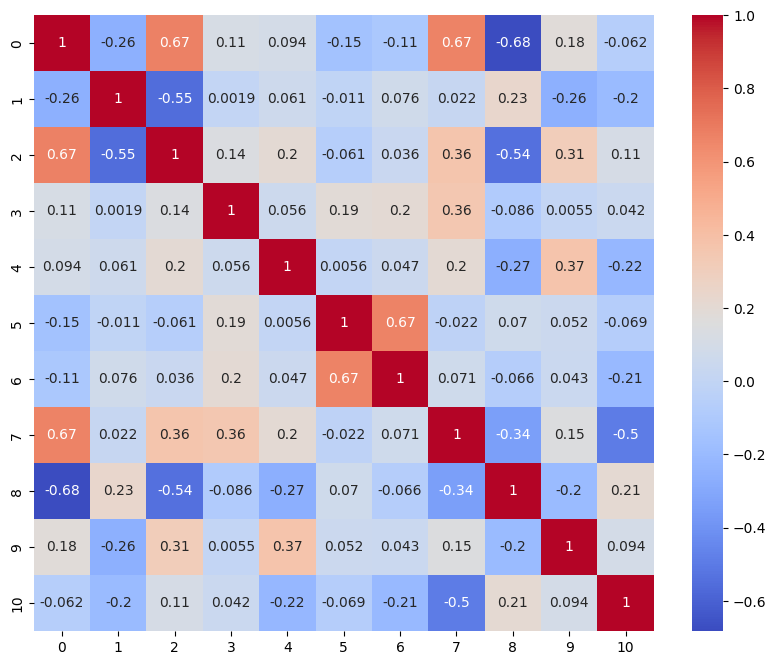

<Axes: >

In [23]:
plt.figure(figsize=(10,8))
sns.heatmap(V,annot=True,cmap='coolwarm') #Heatmap de la matrice de corrélation

Comparaison avec corr_matrix

In [24]:
np.allclose(corr_matrix.to_numpy(),V)

True

les deux matrices de correlation sont égaux

### Diagonalisation de la matrice de corrélation

Décomposition de la matrice de corrélation : V = P D Pᵀ. `P` contient les vecteurs propres (en colonnes) et `D` les valeurs propres.

Comme V est symétrique, `P` est orthogonale : son inverse P⁻¹ est égal à sa transposée Pᵀ.

In [25]:
D, P = np.linalg.eigh(V)      # eigh : V est symétrique
ordre = np.argsort(D)[::-1]   # indices qui trient D par ordre décroissant
D = D[ordre]                  # valeurs propres triées
P = P[:, ordre]               # on réordonne les colonnes de P de la même façon

Quelques calculs matricielles

In [26]:
trace_matrix=np.trace(V)
print(trace_matrix)

11.000000000000002

Somme des valeurs propres doit etre egale a la trace de la matrice de correlation

In [27]:
D.sum()

np.float64(11.000000000000002)

### Taux d'inertie et choix du nombre d'axes

calcul des taux d'inertie de chaque Axe

In [28]:
taux=D/D.sum()*100

In [29]:
taux.round(2)

array([28.17, 17.51, 14.1 , 11.03,  8.72,  6.  ,  5.31,  3.85,  3.13,
        1.65,  0.54])

le cumul doit faire 100

In [30]:
cumul=np.cumsum(taux)

In [31]:
cumul

array([ 28.17393128,  45.68220118,  59.77805108,  70.80743772,
        79.52827474,  85.52471351,  90.83190641,  94.67696732,
        97.81007747,  99.4585608 , 100.        ])

Les 4 premiers axes résument environ 71 % de l'information. Il en faut 6 (85,5 %) pour dépasser 80 %, car 5 axes n'atteignent que 79,5 %.

**Règle de Kaiser :** on garde les axes dont la valeur propre est **supérieure** à la moyenne des valeurs propres (égale à 1 pour une ACP normée).

In [32]:
D.mean()

np.float64(1.0000000000000002)

In [33]:
D

array([3.09913244, 1.92590969, 1.55054349, 1.21323253, 0.95929207,
       0.65960826, 0.58379122, 0.4229567 , 0.34464212, 0.18133317,
       0.05955831])

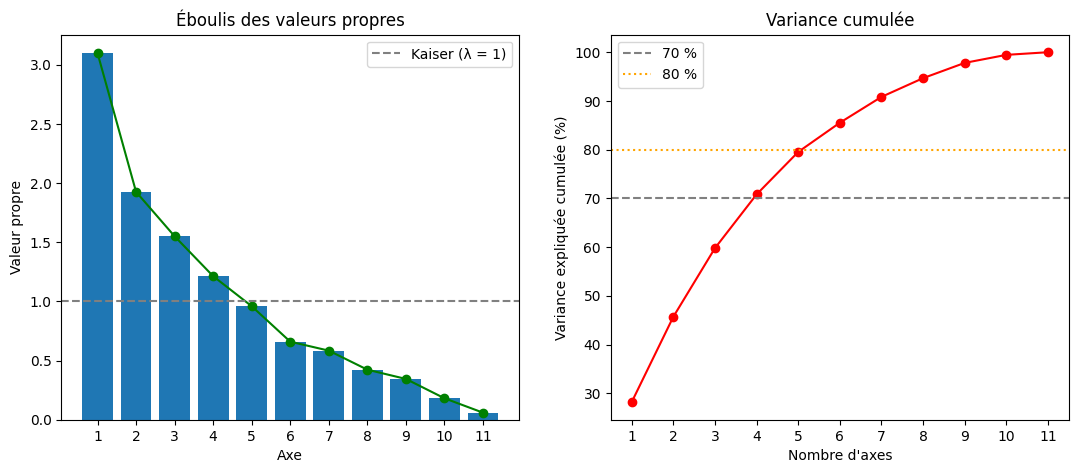

In [34]:
axis=np.arange(1,len(D)+1)
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].plot(axis,D,marker='o',color='green')
axes[0].bar(axis,D)
axes[0].axhline(1,color='gray',linestyle='--',label='Kaiser (λ = 1)')
axes[0].set_xlabel("Axe")
axes[0].set_ylabel("Valeur propre")
axes[0].set_title("Éboulis des valeurs propres")
axes[0].set_xticks(axis)
axes[0].legend()

#Variance cumulée
axes[1].plot(axis,cumul,marker='o',color='red')
#axes[1].bar(axis,D)
axes[1].axhline(70,color='gray',linestyle='--',label='70 %')
axes[1].axhline(80,color='orange',linestyle=':',label='80 %')
axes[1].set_xlabel("Nombre d'axes")
axes[1].set_ylabel("Variance expliquée cumulée (%)")
axes[1].set_title("Variance cumulée")
axes[1].set_xticks(axis)
axes[1].legend()

In [35]:
print("Kaiser (λ > 1) :", (D > 1).sum())
print("Seuil de 70 % :", np.argmax(cumul >= 70) + 1)
print("Seuil de 80 % :", np.argmax(cumul >= 80) + 1)

Kaiser (λ > 1) : 4
Seuil de 70 % : 4
Seuil de 80 % : 6

| Critère | Nombre d'axes |
|---|---|
| Kaiser (λ > 1) | 4 |
| Variance cumulée ≥ 70 % | 4 (70,8 %) |
| Variance cumulée ≥ 80 % | 6 (85,5 %) |
| Coude de l'éboulis | ambigu : cassure après l'axe 2, palier après l'axe 6 |

**Choix : 4 axes**, sur lesquels Kaiser et le seuil de 70 % s'accordent. Ils résument 70,8 % de l'information.

### Composantes principales

Nouveau tableau des vins sur les composantes principales donc 4

In [36]:
C=Xcr@P[:,:4]

In [37]:
pd.DataFrame(C)

             0         1         2         3
0     1.619530  0.450950  1.774454  0.043740
1     0.799170  1.856553  0.911690  0.548066
2     0.748479  0.882039  1.171394  0.411021
3    -2.357673 -0.269976 -0.243489 -0.928450
4     1.619530  0.450950  1.774454  0.043740
...        ...       ...       ...       ...
1594  2.150500  0.814286 -0.617063  0.407687
1595  2.214496  0.893101 -1.807402  0.414003
1596  1.456129  0.311746 -1.124239  0.491877
1597  2.270518  0.979791 -0.627965  0.639770
1598  0.426975 -0.536690 -1.628955 -0.391716

[1599 rows x 4 columns]

In [38]:
#les dimensions dans la nouvelle base
C.shape

(1599, 4)

In [39]:
print("P orthogonale :", np.allclose(P.T @ P, np.eye(11)))
print("V = P D Pᵀ :", np.allclose(P @ np.diag(D) @ P.T, V))
print("Variances de C = valeurs propres :", np.allclose(C.var(axis=0), D[:4]))
print("Composantes décorrélées :", np.allclose(np.corrcoef(C.T), np.eye(4), atol=1e-8))

P orthogonale : True
V = P D Pᵀ : True
Variances de C = valeurs propres : True
Composantes décorrélées : True

Ces quatre vérifications confirment que la diagonalisation est correcte : les vecteurs propres sont orthogonaux, les variances des composantes sont les valeurs propres, et les composantes ne sont pas corrélées entre elles.

## 5. Projections des vins

Avec les 4 axes retenus, on représente les plans 1-2, 1-3, 2-3 et 3-4, puis une projection 3D des axes 1, 2 et 3. La couleur des points est la note de qualité, qui n'entre pas dans l'ACP (variable illustrative).

### Plan 1-2

In [40]:
y=df['quality']

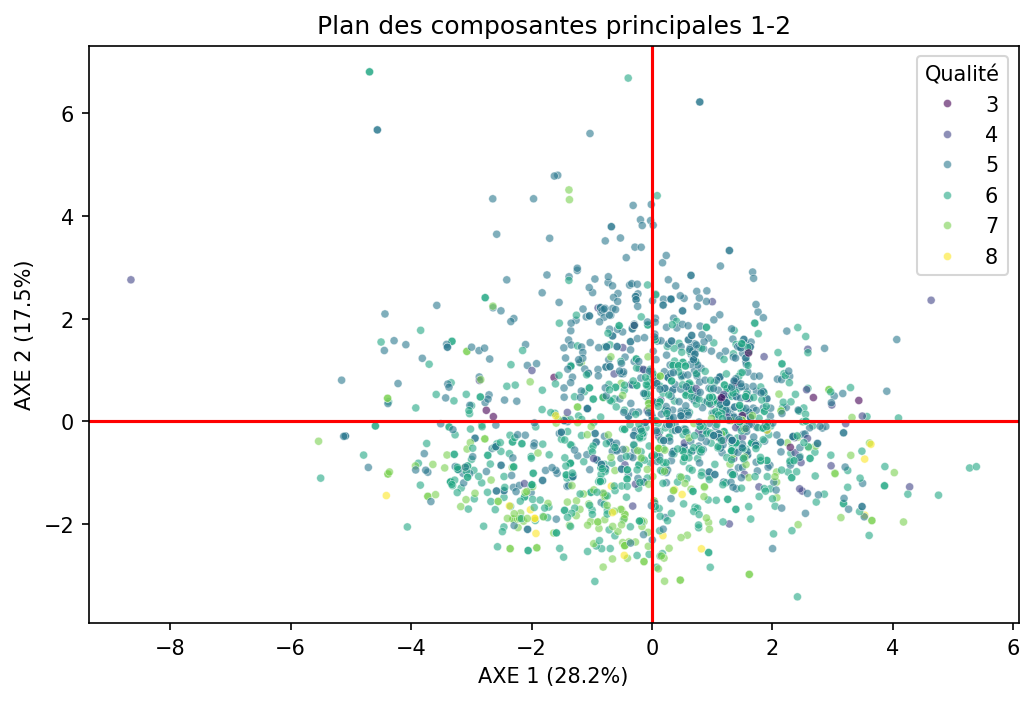

In [41]:
plt.figure(figsize=(8,5),dpi=150)
sns.scatterplot(data=df,x=C[:,0],y=C[:,1],hue='quality',palette='viridis',alpha=0.6,s=15)
plt.axhline(0,color='red')
plt.axvline(0,color='red')
plt.title('Plan des composantes principales 1-2')
plt.xlabel(f"AXE 1 ({taux[0]:.1f}%)")
plt.ylabel(f"AXE 2 ({taux[1]:.1f}%)")
plt.legend(title="Qualité")
plt.savefig("images/plan_1_2.png", dpi=150, bbox_inches="tight")

### Plan 1-3

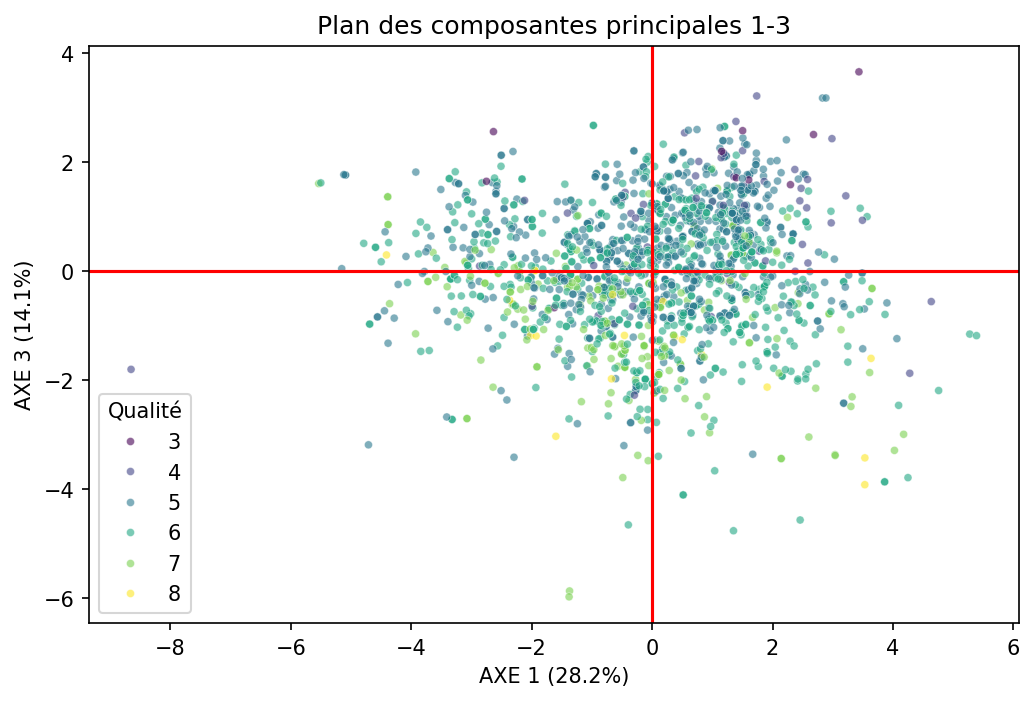

In [42]:
plt.figure(figsize=(8,5),dpi=150)
sns.scatterplot(data=df,x=C[:,0],y=C[:,2],hue='quality',palette='viridis',alpha=0.6,s=15)
plt.axhline(0,color='red')
plt.axvline(0,color='red')
plt.title('Plan des composantes principales 1-3')
plt.xlabel(f"AXE 1 ({taux[0]:.1f}%)")
plt.ylabel(f"AXE 3 ({taux[2]:.1f}%)")
plt.legend(title="Qualité")

### Plan 2-3

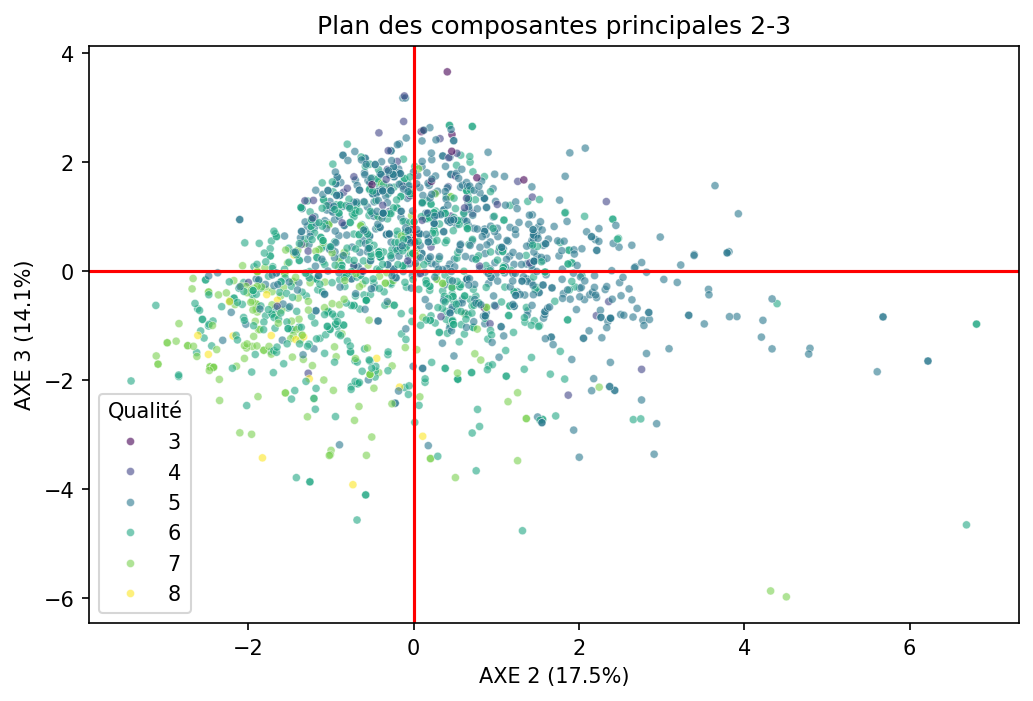

In [43]:
plt.figure(figsize=(8,5),dpi=150)
sns.scatterplot(data=df,x=C[:,1],y=C[:,2],hue='quality',palette='viridis',alpha=0.6,s=15)
plt.axhline(0,color='red')
plt.axvline(0,color='red')
plt.title('Plan des composantes principales 2-3')
plt.xlabel(f"AXE 2 ({taux[1]:.1f}%)")
plt.ylabel(f"AXE 3 ({taux[2]:.1f}%)")
plt.legend(title="Qualité")

### Plan 3-4

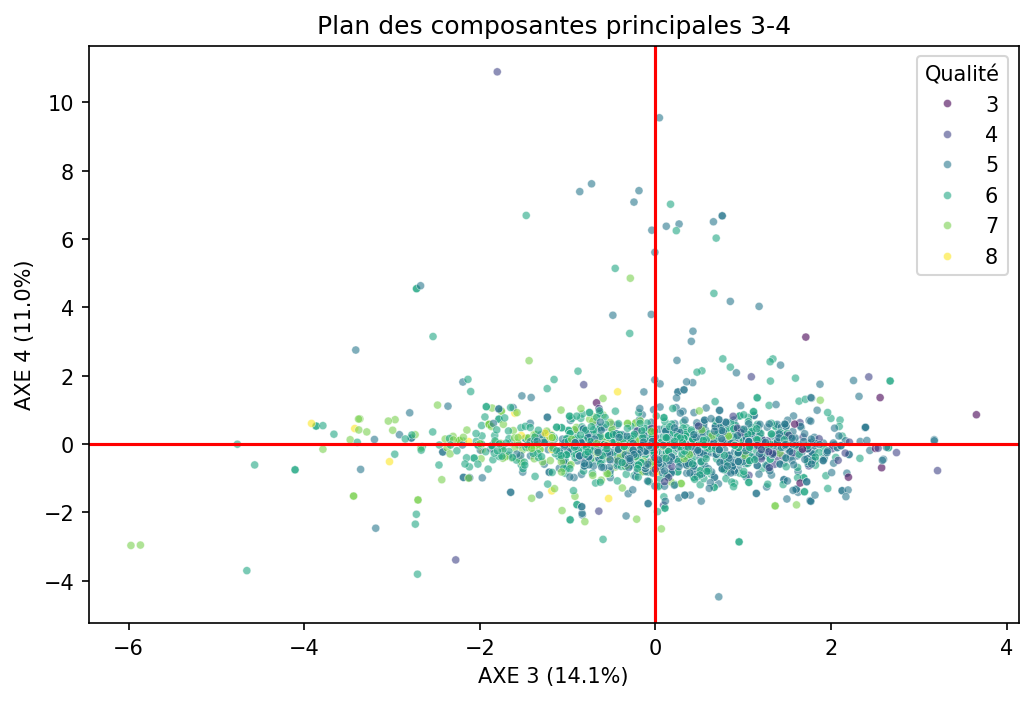

In [44]:
plt.figure(figsize=(8,5),dpi=150)
sns.scatterplot(data=df,x=C[:,2],y=C[:,3],hue='quality',palette='viridis',alpha=0.6,s=15)
plt.axhline(0,color='red')
plt.axvline(0,color='red')
plt.title('Plan des composantes principales 3-4')
plt.xlabel(f"AXE 3 ({taux[2]:.1f}%)")
plt.ylabel(f"AXE 4 ({taux[3]:.1f}%)")
plt.legend(title="Qualité")

### Projection 3D (axes 1, 2 et 3)

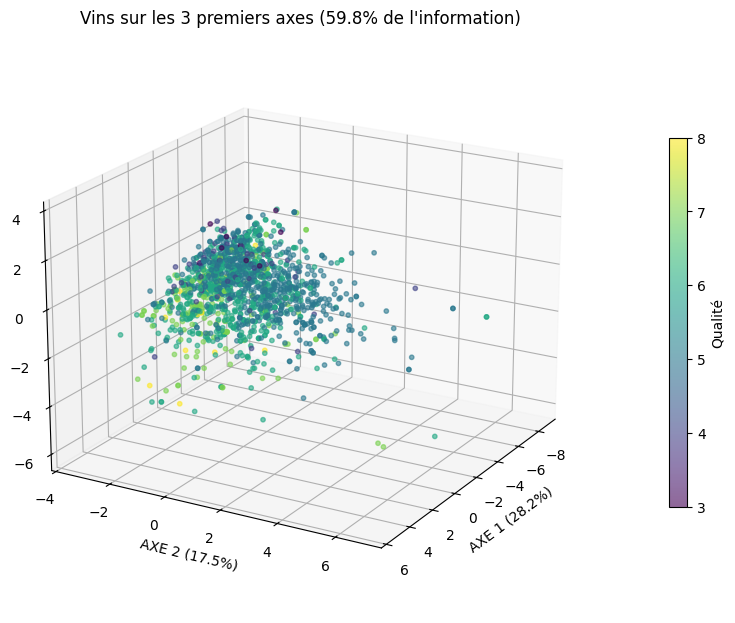

In [45]:
fig=plt.figure(figsize=(10,8))
ax=fig.add_subplot(projection='3d')
sc=ax.scatter(C[:,0],C[:,1],C[:,2],c=y,cmap='viridis',alpha=0.6,s=10)
ax.set_xlabel(f"AXE 1 ({taux[0]:.1f}%)")
ax.set_ylabel(f"AXE 2 ({taux[1]:.1f}%)")
ax.set_zlabel(f"AXE 3({taux[2]:.1f}%)")
ax.set_title(f"Vins sur les 3 premiers axes ({taux[:3].sum():.1f}% de l'information)")
ax.view_init(elev=20,azim=30)
cb = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.1, ticks=[3, 4, 5, 6, 7, 8])
cb.set_label("Qualité")
plt.show()

Version interactive (nécessite `plotly`, non affichée sur GitHub : une copie est enregistrée dans `images/3d.html`).

In [46]:
try:
    import plotly.express as px
    fig = px.scatter_3d(x=C[:, 0], y=C[:, 1], z=C[:, 2], color=y.astype(str),
                        labels={'x': 'Axe 1', 'y': 'Axe 2', 'z': 'Axe 3', 'color': 'Qualité'},
                        opacity=0.6)
    fig.update_traces(marker_size=3)
    fig.write_html("images/3d.html")   # GitHub n'affiche pas plotly : on exporte aussi en HTML
    fig.show()
except ImportError:
    print("plotly n'est pas installé : pip install plotly")

## 6. Cercles des corrélations

In [47]:
L = pd.DataFrame(P[:, :4] * np.sqrt(D[:4]),
                 index=X.columns,
                 columns=['Axe1', 'Axe2', 'Axe3', 'Axe4'])

def cercle(i, j, fichier=None):
    fig, ax = plt.subplots(figsize=(7, 7), dpi=120)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='gray'))
    for nom in L.index:
        x = L.loc[nom].iloc[i]
        y = L.loc[nom].iloc[j]
        bien = x**2 + y**2 > 0.5                      # cos² sur le plan > 0,5 ?
        couleur = 'tab:blue' if bien else 'lightgray'
        ax.arrow(0, 0, x, y, head_width=0.03, color=couleur, length_includes_head=True)
        ax.text(x * 1.08, y * 1.08, nom, fontsize=9, color='black' if bien else 'gray')
    ax.axhline(0, color='gray', lw=0.8)
    ax.axvline(0, color='gray', lw=0.8)
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_xlabel(f"AXE {i+1} ({taux[i]:.1f}%)")
    ax.set_ylabel(f"AXE {j+1} ({taux[j]:.1f}%)")
    ax.set_title(f"Cercle des corrélations, plan {i+1}-{j+1}")
    if fichier:
        plt.savefig(fichier, dpi=150, bbox_inches='tight')
    plt.show()

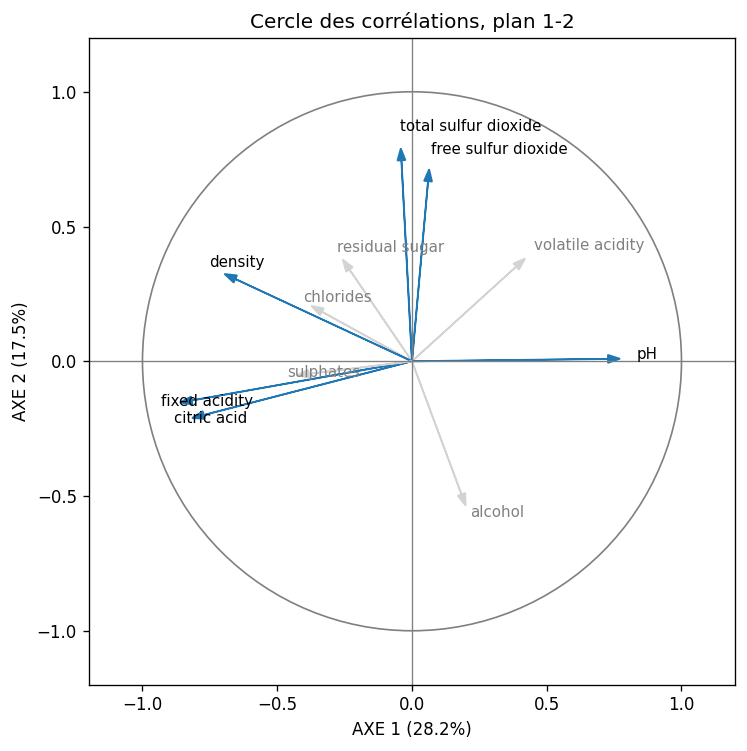

In [48]:
cercle(0, 1, 'images/cercle_1_2.png')   # Plan 1-2

**Plan 1-2 (45,7 % de l'information).** Variables bien représentées (cos² > 0,5) : `fixed acidity` (0,77), `citric acid` (0,71), `total sulfur dioxide` (0,63), `pH` (0,60), `density` (0,59) et `free sulfur dioxide` (0,51).

- **Axe 1 : l'acidité.** À gauche, `fixed acidity` (−0,86), `citric acid` (−0,82) et `density` (−0,70). À droite, `pH` (+0,77) : un pH élevé correspond à un vin moins acide.
- **Axe 2 : le dioxyde de soufre.** `total sulfur dioxide` (+0,79) et `free sulfur dioxide` (+0,71) pointent vers le haut.
- Les flèches de l'acidité et du soufre sont à angle droit : ces deux dimensions ne sont pas liées.
- Les vins les mieux notés sont plutôt en bas du plan, donc moins sulfités, mais le lien reste modéré.

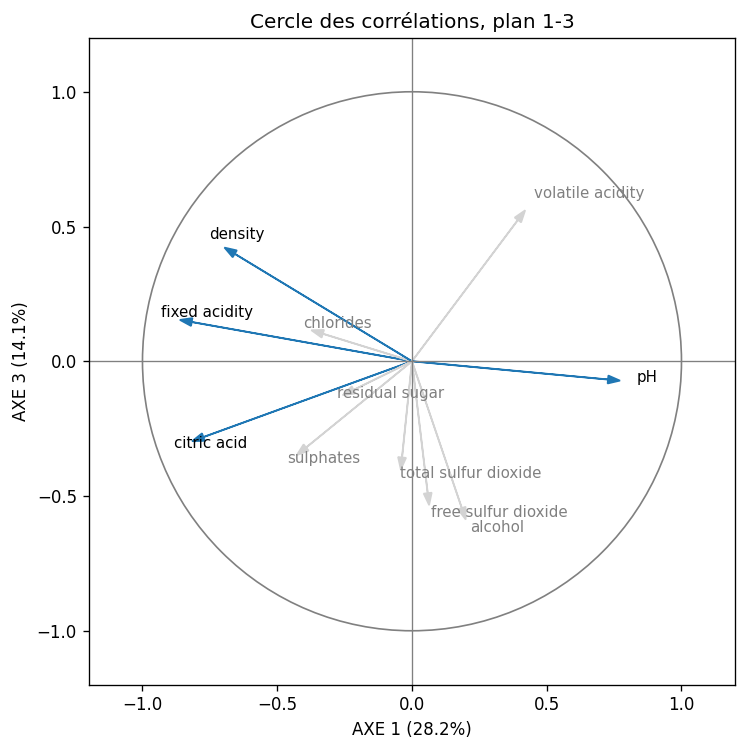

In [49]:
cercle(0, 2)   # Plan 1-3

**Plan 1-3.** Les variables bien représentées (`fixed acidity` 0,77, `citric acid` 0,75, `density` 0,66, `pH` 0,60) sont toutes portées par l'axe 1. L'axe 3 n'est bien expliqué par aucune variable sur ce plan (`volatile acidity` est à la limite, 0,49). Ce plan n'apporte donc rien de plus que l'axe 1.

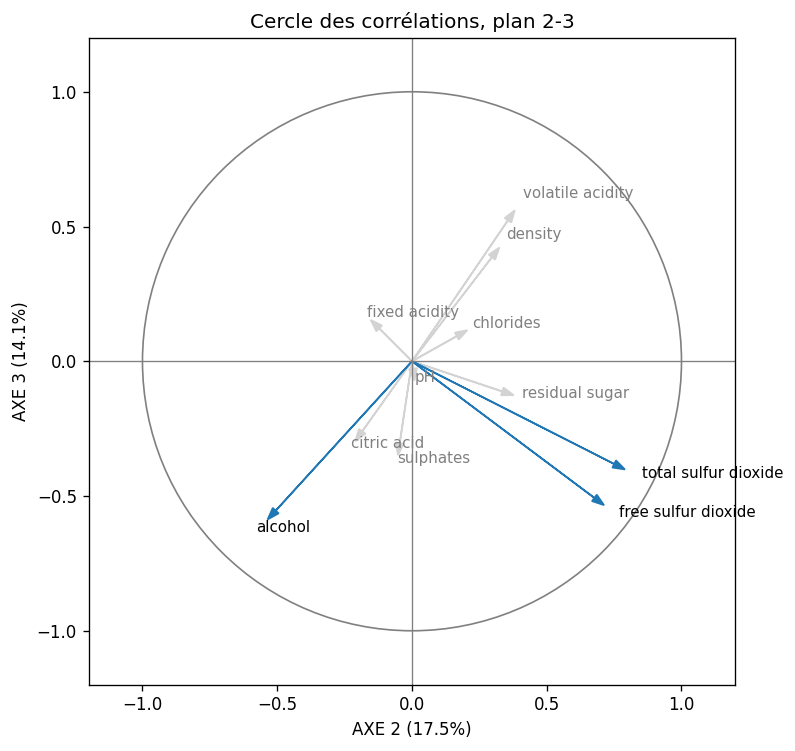

In [50]:
cercle(1, 2)   # Plan 2-3

**Plan 2-3.** Variables bien représentées : `free sulfur dioxide` (0,79), `total sulfur dioxide` (0,79) et `alcohol` (0,63). L'axe 2 reste l'axe du soufre. L'axe 3 oppose l'alcool (−0,59) à l'acidité volatile (+0,56), mais `volatile acidity` n'atteint pas le seuil sur ce plan (0,46). Ce sont les deux axes les plus liés à la note de qualité (voir plus bas).

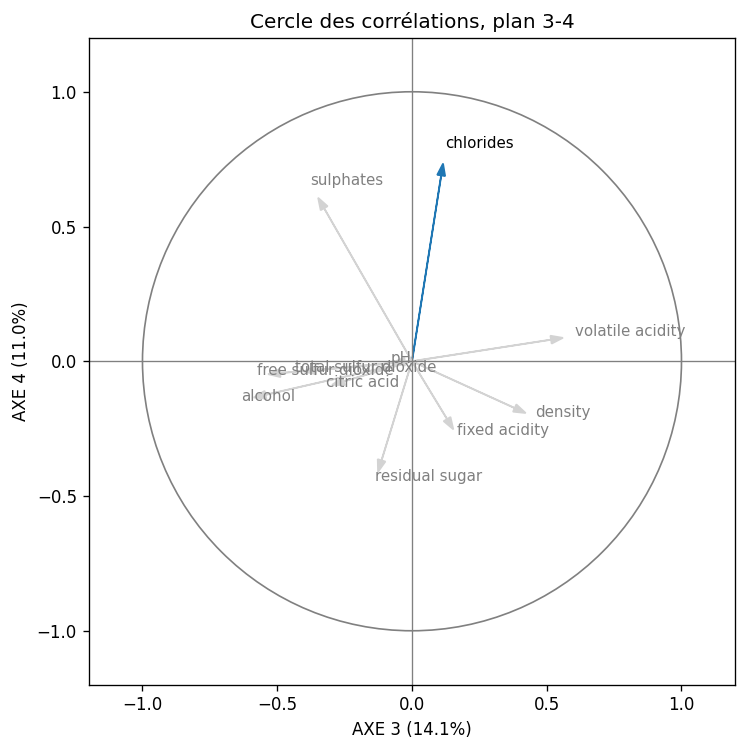

In [51]:
cercle(2, 3)   # Plan 3-4

**Plan 3-4.** Une seule variable est bien représentée : `chlorides` (cos² de 0,55), portée par l'axe 4 (+0,73). Plus un vin est haut sur ce plan, plus il contient de chlorures. L'axe 3 n'est expliqué par aucune variable. La qualité n'est presque pas liée à l'axe 4 : ce plan ne distingue pas les qualités.

Qualité de representation : Cos2

In [52]:
cos2 = L ** 2                                   # cos² de chaque variable sur chaque axe

plans = {'1-2': (0, 1), '1-3': (0, 2), '2-3': (1, 2), '3-4': (2, 3)}
cos2_plans = pd.DataFrame({nom: cos2.iloc[:, i] + cos2.iloc[:, j]
                           for nom, (i, j) in plans.items()})
print(cos2_plans.round(2))

                       1-2   1-3   2-3   3-4
fixed acidity         0.77  0.77  0.05  0.09
volatile acidity      0.32  0.49  0.46  0.32
citric acid           0.71  0.75  0.13  0.10
residual sugar        0.21  0.08  0.16  0.18
chlorides             0.18  0.15  0.06  0.55
free sulfur dioxide   0.51  0.29  0.79  0.29
total sulfur dioxide  0.63  0.16  0.79  0.16
density               0.59  0.66  0.28  0.21
pH                    0.60  0.60  0.01  0.01
sulphates             0.19  0.30  0.12  0.49
alcohol               0.33  0.38  0.63  0.36

### Contributions des variables (CTR)

La contribution d'une variable à un axe est son cos² divisé par la valeur propre de l'axe, en %. Chaque colonne somme à 100 %.

In [53]:
ctr = cos2 / D[:4] * 100        # contributions en %
print(ctr.round(1))
print(ctr.sum().round(1))       # 100 pour chaque axe

                      Axe1  Axe2  Axe3  Axe4
fixed acidity         23.9   1.2   1.5   5.3
volatile acidity       5.7   7.6  20.2   0.6
citric acid           21.5   2.3   5.7   0.6
residual sugar         2.1   7.4   1.0  13.9
chlorides              4.5   2.2   0.9  44.4
free sulfur dioxide    0.1  26.4  18.4   0.2
total sulfur dioxide   0.1  32.4  10.4   0.1
density               15.6   5.5  11.5   3.0
pH                    19.2   0.0   0.3   0.0
sulphates              5.9   0.1   7.8  30.3
alcohol                1.3  14.9  22.2   1.5
Axe1    100.0
Axe2    100.0
Axe3    100.0
Axe4    100.0
dtype: float64

### Lien entre la qualité et les axes

In [54]:
# corrélation de la note de qualité avec chaque composante principale
print([round(np.corrcoef(C[:, k], y)[0, 1], 2) for k in range(4)])

[np.float64(-0.11), np.float64(-0.39), np.float64(-0.4), np.float64(-0.04)]

La note est peu liée à l'axe 1 (−0,11), davantage aux axes 2 (−0,39) et 3 (−0,40), et pas à l'axe 4 (−0,04).

## 7. Vérification avec scikit-learn

ACP avec Scikit-Learn

In [55]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

centrer et réduire

In [56]:
Xs=StandardScaler().fit_transform(X)
print(np.allclose(Xs,Xcr))

True

In [57]:
pca=PCA(n_components=4) # On lui dit de garder 4 axes comme avec Kaiser
C_sk=pca.fit_transform(Xs) #calcule l'ACP c'est l'équivalent de mon C

dimensiion de C_sk doit être la même que pour C

In [58]:
C_sk.shape

(1599, 4)

In [59]:
(100*pca.explained_variance_ratio_).round(1) #taux d'inertie de chaque axe

array([28.2, 17.5, 14.1, 11. ])

In [60]:
pca.explained_variance_.round(3)   # valeurs propres (division par n-1 : très légèrement différentes des nôtres)

array([3.101, 1.927, 1.552, 1.214])

In [61]:
pca.components_.shape #les vecteurs propres

(4, 11)

verification de C et C_sk

In [62]:
np.allclose(np.abs(C_sk),np.abs(C))

True

In [63]:
np.allclose(np.abs(pca.components_), np.abs(P[:, :4].T))   # vecteurs propres, au signe près

True

L'ACP faite à la main et l'ACP de scikit-learn donnent les mêmes résultats : mêmes taux d'inertie, mêmes composantes et mêmes vecteurs propres, **au signe près** (le signe d'un vecteur propre est défini à un facteur −1 près).

Les valeurs propres de scikit-learn sont très légèrement plus grandes (3,101 contre 3,099), car il divise par n−1 et notre calcul par n.

## 8. Vins rouges et blancs

l'ACP sur les deux vins

In [64]:
df_wineBlanc=pd.read_csv('data/winequality-white.csv',sep=';') #importation

In [65]:
df_wineBlanc.head()

   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.0              0.27         0.36  ...       0.45      8.8        6
1            6.3              0.30         0.34  ...       0.49      9.5        6
2            8.1              0.28         0.40  ...       0.44     10.1        6
3            7.2              0.23         0.32  ...       0.40      9.9        6
4            7.2              0.23         0.32  ...       0.40      9.9        6

[5 rows x 12 columns]

Ce fichier a les mêmes colonnes que le précédent : on peut donc les concaténer.

In [66]:
df_wineRouge=df.copy()

On ajoute le type de chaque vin (la colonne `type` ne servira qu'à colorer les graphiques).

In [67]:
df_wineBlanc['type']='blanc'
df_wineRouge['type']='rouge'

In [68]:
df_wine=pd.concat([df_wineRouge,df_wineBlanc],ignore_index=True)

In [69]:
df_wine

      fixed acidity  volatile acidity  citric acid  ...  alcohol  quality   type
0               7.4              0.70         0.00  ...      9.4        5  rouge
1               7.8              0.88         0.00  ...      9.8        5  rouge
2               7.8              0.76         0.04  ...      9.8        5  rouge
3              11.2              0.28         0.56  ...      9.8        6  rouge
4               7.4              0.70         0.00  ...      9.4        5  rouge
...             ...               ...          ...  ...      ...      ...    ...
6492            6.2              0.21         0.29  ...     11.2        6  blanc
6493            6.6              0.32         0.36  ...      9.6        5  blanc
6494            6.5              0.24         0.19  ...      9.4        6  blanc
6495            5.5              0.29         0.30  ...     12.8        7  blanc
6496            6.0              0.21         0.38  ...     11.8        6  blanc

[6497 rows x 13 columns]

On a maintenant 6497 vins et 13 colonnes.

In [70]:
df_wine['type'].value_counts()

type
blanc    4898
rouge    1599
Name: count, dtype: int64

On a 4898 vins blancs et 1599 vins rouges.

In [71]:
print("Doublons (rouge + blanc) :", df_wine.drop(columns="type").duplicated().sum())

Doublons (rouge + blanc) : 1179

Les doublons sont conservés, comme pour les vins rouges seuls.

ACP sur les 6497 Vins

In [72]:
X1=df_wine.drop(['type','quality'],axis=1)
y1=df_wine['type']

On centre et on réduit

In [73]:
Xs1=StandardScaler().fit_transform(X1)

In [74]:
pca1=PCA(n_components=4)
C1=pca1.fit_transform(Xs1)


In [75]:
C1.shape

(6497, 4)

In [76]:
#Valeurs propres
(pca1.explained_variance_).round(2)

array([3.03, 2.49, 1.56, 0.97])

In [77]:
#vecteurs propres
pca1.components_.shape

(4, 11)

In [78]:
pca_full = PCA().fit(Xs1)                # toutes les composantes, pour appliquer Kaiser
vp = pca_full.explained_variance_
print(vp.round(2))
print("Kaiser (λ > 1) :", (vp > 1).sum())

[3.03 2.49 1.56 0.97 0.72 0.61 0.52 0.5  0.34 0.23 0.03]
Kaiser (λ > 1) : 3

Sur l'ensemble rouge + blanc, Kaiser ne garde que 3 axes (la quatrième valeur propre vaut 0,97). On conserve tout de même 4 axes, par cohérence avec l'ACP précédente : ils résument 73,2 % de l'information.

taux d'inertie ou variance expliquée

In [79]:
print((100 * pca1.explained_variance_ratio_).round(1))     # taux d'inertie de chaque axe
print((100 * pca1.explained_variance_ratio_.sum()).round(1))   # total des 4 axes

[27.5 22.7 14.1  8.8]
73.2

Les 4 axes représentent 73,2 % de l'information.

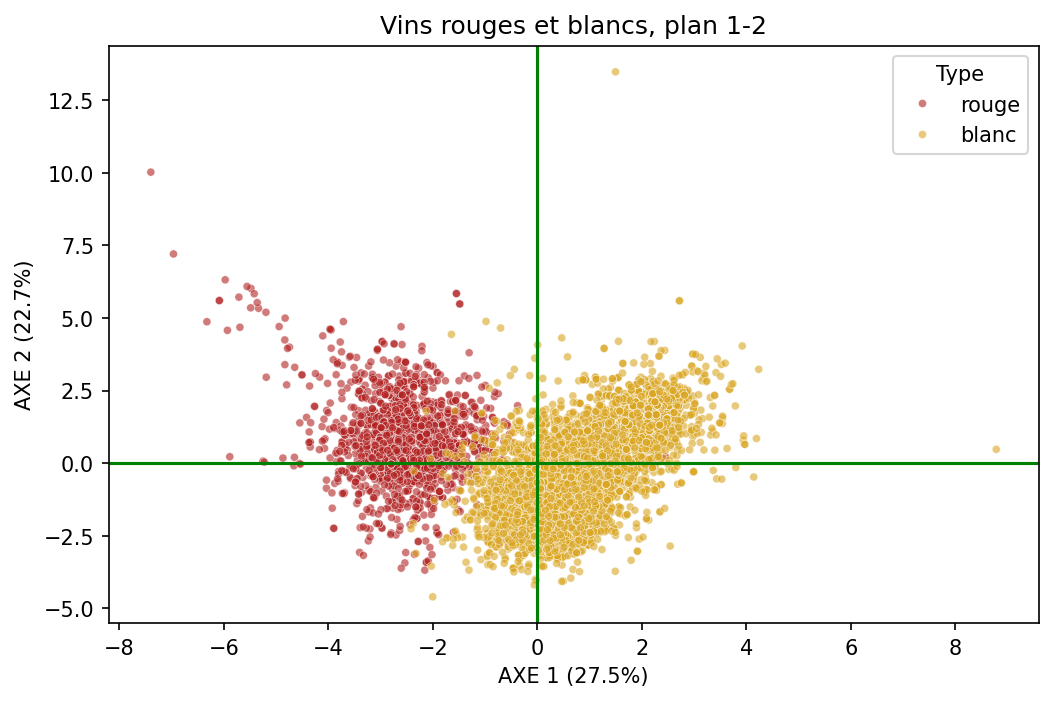

In [80]:
plt.figure(figsize=(8,5),dpi=150)
sns.scatterplot(data=df_wine,x=C1[:,0],y=C1[:,1],hue='type',palette={'rouge': 'firebrick', 'blanc': 'goldenrod'},alpha=0.6,s=15)
plt.axhline(0,color='green')
plt.axvline(0,color='green')
plt.title('Vins rouges et blancs, plan 1-2')
plt.xlabel(f"AXE 1 ({100 * pca1.explained_variance_ratio_[0]:.1f}%)")
plt.ylabel(f"AXE 2 ({100 * pca1.explained_variance_ratio_[1]:.1f}%)")
plt.legend(title="Type")
plt.savefig("images/rouge_blanc_plan_1_2.png", dpi=150, bbox_inches="tight")

Matrice de corrélation Variables Axes

In [81]:
L1= pd.DataFrame(pca1.components_ .T * np.sqrt(pca1.explained_variance_),
                 index=X1.columns,
                 columns=['Axe1', 'Axe2', 'Axe3', 'Axe4'])

In [82]:
L1

                          Axe1      Axe2      Axe3      Axe4
fixed acidity        -0.415698  0.531207  0.541848 -0.161921
volatile acidity     -0.662817  0.185647 -0.383347 -0.209645
citric acid           0.265276  0.289486  0.736814  0.260400
residual sugar        0.602172  0.521036 -0.205471 -0.164972
chlorides            -0.505024  0.497889 -0.020809  0.241132
free sulfur dioxide   0.750129  0.113604 -0.167462  0.352006
total sulfur dioxide  0.848490  0.137820 -0.134073  0.205344
density              -0.078225  0.922374 -0.219091 -0.071652
pH                   -0.380686 -0.246165 -0.568077  0.408433
sulphates            -0.512026  0.302778  0.087387  0.631083
alcohol              -0.185284 -0.734469  0.325757  0.105226

### Cercle des corrélations (rouge + blanc)

In [83]:
cos2_1 = L1 ** 2
print((cos2_1['Axe1'] + cos2_1['Axe2']).round(2).sort_values(ascending=False))   # cos² sur le plan 1-2

density                 0.86
total sulfur dioxide    0.74
residual sugar          0.63
free sulfur dioxide     0.58
alcohol                 0.57
chlorides               0.50
volatile acidity        0.47
fixed acidity           0.45
sulphates               0.35
pH                      0.21
citric acid             0.15
dtype: float64

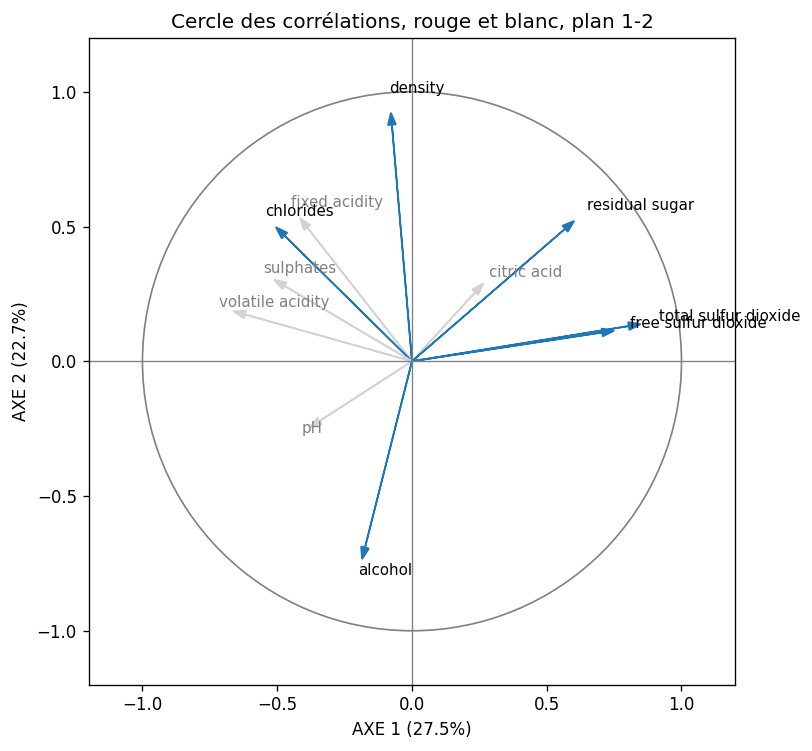

In [84]:
def cercle_g(L_, taux_, i, j, fichier=None):
    fig, ax = plt.subplots(figsize=(7, 7), dpi=120)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='gray'))
    for nom in L_.index:
        x = L_.loc[nom].iloc[i]
        y_ = L_.loc[nom].iloc[j]
        bien = x**2 + y_**2 > 0.5
        ax.arrow(0, 0, x, y_, head_width=0.03, color='tab:blue' if bien else 'lightgray', length_includes_head=True)
        ax.text(x * 1.08, y_ * 1.08, nom, fontsize=9, color='black' if bien else 'gray')
    ax.axhline(0, color='gray', lw=0.8)
    ax.axvline(0, color='gray', lw=0.8)
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_xlabel(f"AXE {i+1} ({taux_[i]:.1f}%)")
    ax.set_ylabel(f"AXE {j+1} ({taux_[j]:.1f}%)")
    ax.set_title(f"Cercle des corrélations, rouge et blanc, plan {i+1}-{j+1}")
    if fichier:
        plt.savefig(fichier, dpi=150, bbox_inches='tight')
    plt.show()

taux1 = 100 * pca1.explained_variance_ratio_
cercle_g(L1, taux1, 0, 1, 'images/cercle_rouge_blanc_1_2.png')

Mesure de séparation

In [85]:
for k in range(2):
  print(f"Axe{k+1} :rouge={C1[df_wine['type']=='rouge',k].mean():.2f},"
  f"blanc={C1[df_wine['type']=='blanc',k].mean():.2f}")

Axe1 :rouge=-2.51,blanc=0.82
Axe2 :rouge=0.78,blanc=-0.25

**Interprétation.** L'axe 1 sépare nettement les deux types de vin : la moyenne vaut −2,51 pour les rouges et +0,82 pour les blancs.

- **Côté blancs :** `total sulfur dioxide` (+0,85), `free sulfur dioxide` (+0,75) et `residual sugar` (+0,60).
- **Côté rouges :** `chlorides` (−0,51, à la limite du seuil) et `volatile acidity` (−0,66, cos² de 0,47, juste sous le seuil).
- `density` et `alcohol` sont bien représentées, mais portées par l'axe 2, qui sépare beaucoup moins les deux types.

L'ACP retrouve donc seule la distinction rouge/blanc, sans avoir reçu le type de vin.

## 9. Conclusion et limites

**Conclusion**

- 4 axes (Kaiser et seuil de 70 %) résument 70,8 % de l'information des 11 mesures chimiques des vins rouges.
- L'axe 1 (28,2 %) est l'axe de l'acidité, l'axe 2 (17,5 %) celui du dioxyde de soufre. Ces deux dimensions sont indépendantes.
- La qualité est liée modérément aux axes 2 et 3 (corrélations de −0,39 et −0,40) et très peu à l'axe 1 (−0,11).
- L'ACP sur les 6497 vins sépare nettement rouges et blancs sur l'axe 1 : les blancs contiennent plus de dioxyde de soufre et de sucre, les rouges plus de chlorures et d'acidité volatile.
- L'ACP faite à la main est validée par scikit-learn.

**Limites**

- Corrélation n'est pas causalité.
- Le plan 1-2 ne montre que 45,7 % de l'information : le nuage se lit comme une tendance, pas vin par vin.
- La note de qualité est subjective, et plus de 80 % des vins rouges sont notés 5 ou 6.
- L'ACP est sensible aux valeurs extrêmes, conservées ici : leur influence n'a pas été testée.
- Les axes 3 et 4 sont difficiles à interpréter.
- Les résultats concernent les *vinho verde* portugais.